# Phase 4 - PPO vs DQN vs Avellaneda-Stoikov

We now add a second learner of a fundamentally different type and run the full bake-off.

| | Avellaneda-Stoikov | DQN | PPO |
|---|---|---|---|
| type | closed-form | value-based RL | policy-gradient RL |
| action | continuous (gridded) | **discrete** (16 actions) | **continuous** (2-D Gaussian) |
| learns | nothing | $Q(s,a)$, act greedily | a stochastic policy directly |

**Why try PPO at all?** The natural market-making action - how far to place each quote - is continuous. DQN forces it onto a coarse grid; PPO outputs a smooth distribution over offsets and improves it with a clipped trust-region update. The question is whether that buys anything here.

**Fair comparison.** The market's randomness (fundamental path, order flow) is drawn independently of the agent's action, so a given seed produces an *identical* market in both discrete and continuous env modes. We evaluate every agent on the same seed set.

> Trained by `scripts/train_dqn.py` and `scripts/train_ppo.py`.

In [1]:
import json, pathlib
import numpy as np
import matplotlib.pyplot as plt

from quant_mm.sim import MarketMakingEnv, MMEnvConfig
from quant_mm.agents import DQN, PPO, AvellanedaStoikovAgent, ASConfig, FixedSymmetricAgent
from quant_mm.eval import run_episode, evaluate, summary_table

def find(d):
    return next(p for p in [pathlib.Path(d), pathlib.Path('..') / d] if p.exists())

env_d = MarketMakingEnv(MMEnvConfig(continuous_action=False))   # DQN / AS / Fixed
env_c = MarketMakingEnv(MMEnvConfig(continuous_action=True))    # PPO
cfg = env_d.cfg

dqn = DQN.load(str(find('runs/dqn') / 'dqn.pt'))
ppo = PPO.load(str(find('runs/ppo') / 'ppo.pt'))
ppo_hist = json.loads((find('runs/ppo') / 'history.json').read_text())
as_agent = AvellanedaStoikovAgent(cfg, ASConfig(gamma=0.1, kappa=40.0))
print('DQN params:', sum(p.numel() for p in dqn.online.parameters()), '| PPO params:', sum(p.numel() for p in ppo.net.parameters()))

DQN params: 19472 | PPO params: 17797


## 1. The three-way bake-off (identical seeds)

In [2]:
N = 300
results = {
    'Fixed(3 ticks)': evaluate(env_d, FixedSymmetricAgent(cfg, 3), n_episodes=N, seed0=2_000_000),
    'Avellaneda-Stoikov': evaluate(env_d, as_agent, n_episodes=N, seed0=2_000_000),
    'DQN (discrete)': evaluate(env_d, dqn, n_episodes=N, seed0=2_000_000),
    'PPO (continuous)': evaluate(env_c, ppo, n_episodes=N, seed0=2_000_000),
}
print(summary_table(results))

agent                             pnl_mean             pnl_std              sharpe            win_rate  mean_abs_inventory           avg_fills
----------------------------------------------------------------------------------------------------------------------------------------------
Fixed(3 ticks)                     11.5754              4.2136              2.7472              0.9867             19.7425            500.1433
Avellaneda-Stoikov                 10.3872              1.6009              6.4885              1.0000              6.6330            588.4300
DQN (discrete)                      9.8096              1.6176              6.0643              1.0000              5.8990            427.5533
PPO (continuous)                   11.0904              1.7499              6.3378              1.0000              7.5801            539.8433


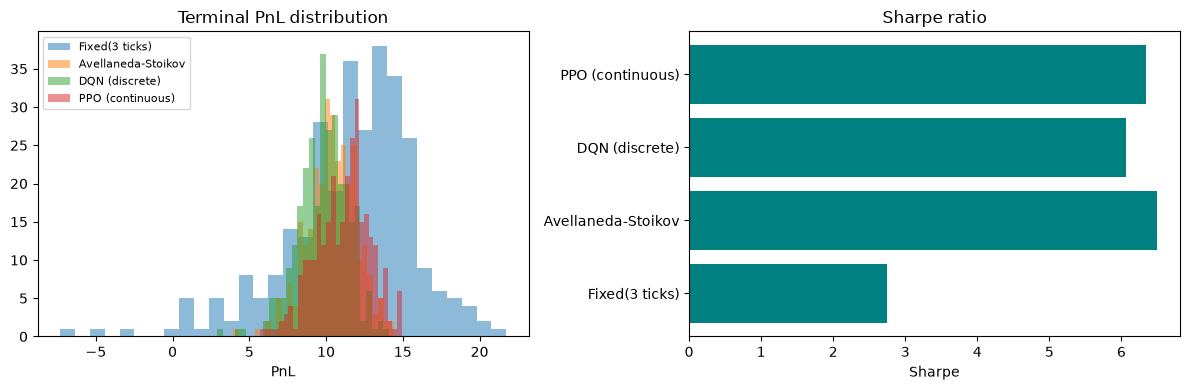

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, r in results.items():
    axes[0].hist(r['pnls'], bins=30, alpha=0.5, label=name)
axes[0].set_title('Terminal PnL distribution'); axes[0].set_xlabel('PnL'); axes[0].legend(fontsize=8)
names = list(results); sharpes = [results[n]['sharpe'] for n in names]
axes[1].barh(names, sharpes, color='teal'); axes[1].set_title('Sharpe ratio'); axes[1].set_xlabel('Sharpe')
plt.tight_layout(); plt.show()

## 2. Discrete vs continuous quoting policy
DQN can only choose integer tick offsets, so its inventory skew is a **step function**. PPO outputs continuous offsets, so its skew is **smooth**. Both should lean the same way: wider bid / tighter ask when long.

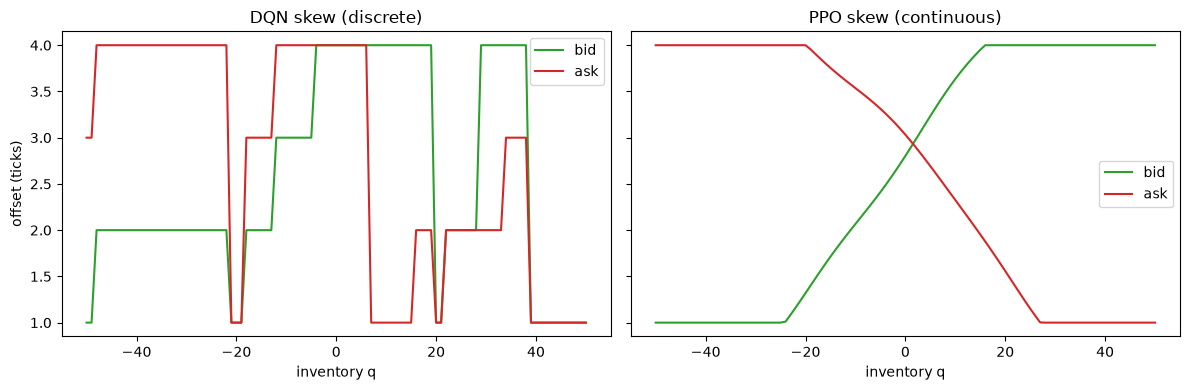

In [4]:
qs = np.arange(-cfg.max_inventory, cfg.max_inventory + 1)
dqn_bid, dqn_ask, ppo_bid, ppo_ask = [], [], [], []
span = cfg.n_offsets - 1
for q in qs:
    obs = np.array([q / cfg.max_inventory, 0, 0.3, 0.5, 0, 1], dtype=np.float32)
    b, k = divmod(dqn.act(obs), cfg.n_offsets); dqn_bid.append(b + 1); dqn_ask.append(k + 1)
    a = ppo.act(obs)  # in [-1,1] -> [1, n_offsets] ticks (continuous)
    ppo_bid.append(1 + (a[0] + 1) / 2 * span); ppo_ask.append(1 + (a[1] + 1) / 2 * span)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
axes[0].plot(qs, dqn_bid, label='bid', color='tab:green'); axes[0].plot(qs, dqn_ask, label='ask', color='tab:red')
axes[0].set_title('DQN skew (discrete)'); axes[0].set_xlabel('inventory q'); axes[0].set_ylabel('offset (ticks)'); axes[0].legend()
axes[1].plot(qs, ppo_bid, label='bid', color='tab:green'); axes[1].plot(qs, ppo_ask, label='ask', color='tab:red')
axes[1].set_title('PPO skew (continuous)'); axes[1].set_xlabel('inventory q'); axes[1].legend()
plt.tight_layout(); plt.show()

## 3. PPO learning curve

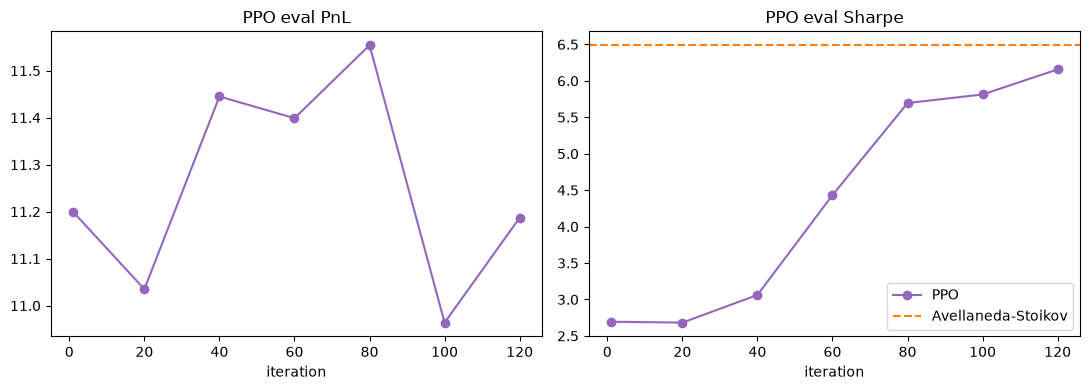

In [5]:
as_sharpe = results['Avellaneda-Stoikov']['sharpe']
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(ppo_hist['iter'], ppo_hist['eval_pnl'], 'o-', color='tab:purple')
axes[0].set_title('PPO eval PnL'); axes[0].set_xlabel('iteration')
axes[1].plot(ppo_hist['iter'], ppo_hist['eval_sharpe'], 'o-', color='tab:purple', label='PPO')
axes[1].axhline(as_sharpe, ls='--', color='tab:orange', label='Avellaneda-Stoikov')
axes[1].set_title('PPO eval Sharpe'); axes[1].set_xlabel('iteration'); axes[1].legend()
plt.tight_layout(); plt.show()

## 4. One market, three agents
Same seed (identical price path and flow) for AS, DQN, and PPO.

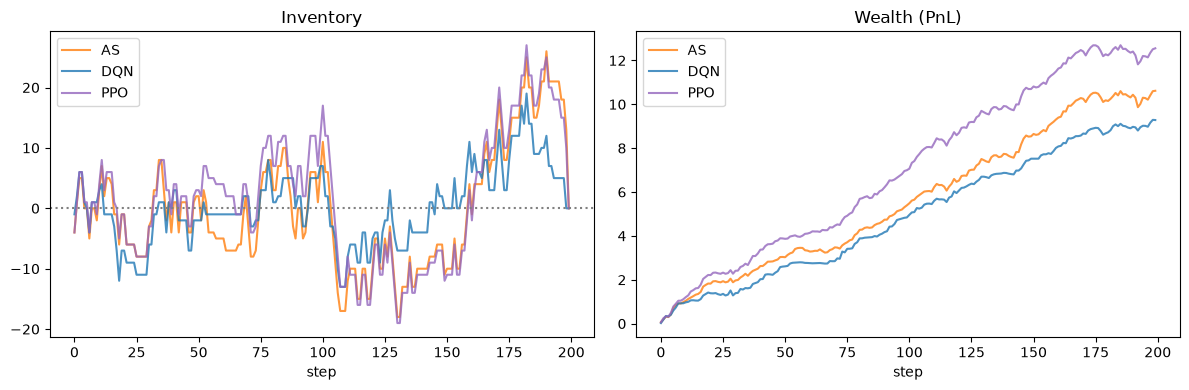

terminal PnL  AS 10.615 | DQN 9.281 | PPO 12.552


In [6]:
seed = 2_222
ep_as = run_episode(env_d, as_agent, seed=seed)
ep_dqn = run_episode(env_d, dqn, seed=seed)
ep_ppo = run_episode(env_c, ppo, seed=seed)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ep, name, c in [(ep_as, 'AS', 'tab:orange'), (ep_dqn, 'DQN', 'tab:blue'), (ep_ppo, 'PPO', 'tab:purple')]:
    axes[0].plot(ep.inventory, label=name, color=c, alpha=0.8)
    axes[1].plot(ep.wealth, label=name, color=c, alpha=0.8)
axes[0].axhline(0, ls=':', color='gray'); axes[0].set_title('Inventory'); axes[0].set_xlabel('step'); axes[0].legend()
axes[1].set_title('Wealth (PnL)'); axes[1].set_xlabel('step'); axes[1].legend()
plt.tight_layout(); plt.show()
print(f'terminal PnL  AS {ep_as.terminal_pnl:.3f} | DQN {ep_dqn.terminal_pnl:.3f} | PPO {ep_ppo.terminal_pnl:.3f}')

---
**Takeaway.** Two reinforcement learners of different families - value-based (DQN) and policy-gradient (PPO) - both learn to quote and manage inventory from reward alone, landing in the neighbourhood of the analytic Avellaneda-Stoikov optimum. PPO's continuous policy gives a smooth inventory skew; DQN's is a coarser step function. The comparison table quantifies the risk-adjusted tradeoffs.

Next: **Phase 5** - validate the agents out-of-distribution via historical-style LOB replay.